# ECE 539 G22: SMS spam detection pilot

**November 22, 2026.** This notebook reviews real saved local experiments and provides optional full reproduction commands. It does not claim that the team has completed the project. Work for this checkpoint was AI-assisted.

Dataset: [Almeida & Hidalgo (2011), UCI SMS Spam Collection](https://doi.org/10.24432/C5CC84), CC BY 4.0. Only training and validation data inform model development; the test partition remains reserved. Saved output cells below are produced by loading recorded artifacts, not by fabricating training results.

In [1]:
from pathlib import Path
import json, sys, subprocess
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
assert (ROOT / 'train_cnn.py').exists(), 'Open this notebook from the project directory.'
def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding='utf-8'))
print('Project directory:', ROOT.name)

Project directory: project


## Reproduce the experiments (optional)

Leave `RUN_TRAINING = False` to inspect the archived run. Set it to `True` to rerun the data audit, baseline and CNN with your active Python environment. This replaces saved experiment artifacts. Use the versions in `requirements.txt`; model outputs may differ across environments. Neither model script evaluates the test partition.

In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    commands = [['src/prepare_data.py'], ['src/train_baseline.py'], ['train_cnn.py', '--overwrite']]
    for arguments in commands:
        subprocess.run([sys.executable, *arguments], cwd=ROOT, check=True)
else:
    print('Displaying the archived pilot; training was not rerun by this notebook.')

Displaying the archived pilot; training was not rerun by this notebook.


## Data audit and fixed partitions

Lowercase and normalize whitespace; group by normalized text, collapse consistent-label duplicates, and exclude conflicting-label groups if any. Split only after deduplication. Stratification is performed within each class using the documented deterministic seed-539 allocation. Features and vocabulary are fit only on training rows.

In [3]:
audit = read_json('artifacts/data_audit.json')
print('Raw records:', audit['counts']['raw_physical_lines'])
print('Removed redundant rows:', audit['counts']['consistent_duplicate_rows_removed'])
print('Unique messages:', audit['counts']['clean_unique_rows'])
splits = pd.DataFrame([{'partition': name, 'messages': value['count'], **value['label_counts']} for name, value in audit['splits'].items()])
display(splits)
assert all(count == 0 for pair in audit['overlap_counts'].values() for count in pair.values())
print('All recorded cross-partition ID and normalized-text overlap counts are zero.')
print('Official ZIP SHA-256:', audit['dataset']['raw_files']['sms_spam_collection.zip']['sha256'])

Raw records: 5574
Removed redundant rows: 415
Unique messages: 5159
All recorded cross-partition ID and normalized-text overlap counts are zero.
Official ZIP SHA-256: 1587ea43e58e82b14ff1f5425c88e17f8496bfcdb67a583dbff9eefaf9963ce3


,partition,messages,ham,spam
0,train,3612,3162,450
1,validation,774,678,96
2,test,773,677,96


## Fixed-threshold validation comparison

Spam is the positive class. Both models use the same validation messages and threshold 0.5. Ham FPR is the proportion of actual ham incorrectly classified as spam. The CNN checkpoint was selected on validation loss, so these are development results, not an independent generalization estimate.

In [4]:
baseline = read_json('artifacts/baseline_metrics.json')
cnn = read_json('artifacts/cnn_pilot/metrics.json')
b = baseline['validation_default_0_5']
c = cnn['validation_fixed_threshold']
assert cnn['test_evaluated'] is False
comparison = pd.DataFrame([
    {'model':'TF-IDF + logistic regression', 'precision':b['spam_precision'], 'recall':b['spam_recall'], 'F1':b['spam_f1'], 'ham_FPR':b['ham_false_positive_rate']},
    {'model':'CNN pilot', 'precision':c['spam_precision'], 'recall':c['spam_recall'], 'F1':c['spam_f1'], 'ham_FPR':c['fp']/(c['tn']+c['fp'])}
]).set_index('model')
display(comparison.round(4))
print('CNN epoch chosen by validation loss:', cnn['best_epoch'])
print('No test evaluation:', not cnn['test_evaluated'])

CNN epoch chosen by validation loss: 11
No test evaluation: True


,precision,recall,F1,ham_FPR
model,,,,
TF-IDF + logistic regression,0.9175,0.9271,0.9223,0.0118
CNN pilot,1.0000,0.8229,0.9029,0.0000


## Confusion matrices

Rows are true ham/spam; columns are predicted ham/spam. Inspect both missed spam and legitimate messages incorrectly flagged; accuracy alone is insufficient for this imbalanced data.

In [5]:
bc = b['confusion_matrix']
for name, values in [('Baseline', [[bc['true_ham_pred_ham_tn'],bc['true_ham_pred_spam_fp']],[bc['true_spam_pred_ham_fn'],bc['true_spam_pred_spam_tp']]]), ('CNN',c['confusion_matrix'])]:
    print(name)
    display(pd.DataFrame(values, index=['true ham','true spam'], columns=['predicted ham','predicted spam']))

Baseline
CNN


,predicted ham,predicted spam
true ham,670,8
true spam,7,89


,predicted ham,predicted spam
true ham,678,0
true spam,17,79


## CNN architecture and learning curve

128 token IDs → embedding (64) → Conv1D (64 filters, width 3) → ReLU → masked max pooling → dropout 0.3 → linear logit. Training uses BCEWithLogitsLoss and Adam at 0.001; probabilities use sigmoid. Padding-centered convolution features cannot win the max pool. No-token inputs are explicitly handled.

Invariant checks: {'padded_positions_cannot_win_pooling': True, 'all_padding_pool_is_zero_and_logits_finite': True, 'adding_padding_preserves_prediction': True, 'vocabulary_fitted_only_on_supplied_training_rows': True, 'test_partition_rejected_before_file_access': True}


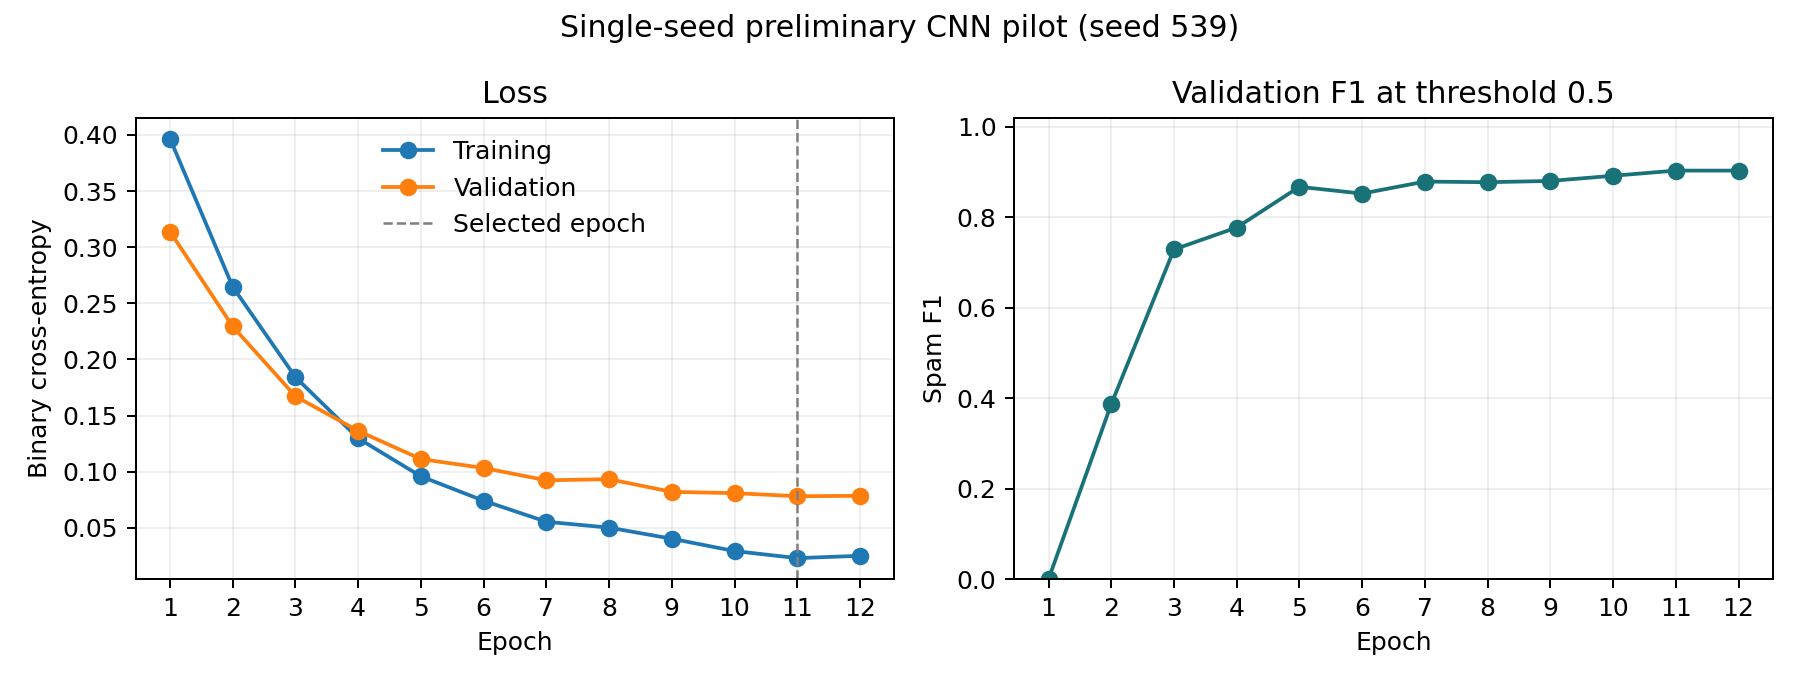

,epoch,training_loss,validation_loss,validation_spam_f1_at_0.5,validation_spam_precision_at_0.5,validation_spam_recall_at_0.5,epoch_seconds
0,1,0.396774,0.313928,0.000000,0.000000,0.000000,0.512928
1,2,0.264718,0.229425,0.386555,1.000000,0.239583,0.574648
2,3,0.184280,0.167198,0.728477,1.000000,0.572917,0.632874
3,4,0.129771,0.136401,0.777070,1.000000,0.635417,0.577735
4,5,0.095906,0.111284,0.867052,0.974026,0.781250,0.503116
5,6,0.074198,0.103382,0.852071,0.986301,0.750000,0.507580
6,7,0.055473,0.092396,0.878613,0.987013,0.791667,0.498745
7,8,0.050254,0.093404,0.877193,1.000000,0.781250,0.496791
8,9,0.040358,0.082095,0.880000,0.974684,0.802083,0.528536
9,10,0.029371,0.080960,0.891429,0.987342,0.812500,0.502416


In [6]:
display(Image(filename=str(ROOT / 'artifacts/cnn_pilot/learning_curve.png')))
display(pd.read_csv(ROOT / 'artifacts/cnn_pilot/learning_curve.csv'))
print('Invariant checks:', read_json('artifacts/cnn_pilot/invariant_checks.json'))

## Validation threshold exploration (not a final result)

These thresholds were selected using the same validation data on which the metrics are displayed. Their scores are tuning-optimistic. The baseline searches all observed validation scores; the CNN uses a fixed 0.05-step grid. Therefore the fixed-0.5 table above is the primary comparison, not a comparison of tuning procedures.

In [7]:
for name, result in [('Baseline',baseline['validation_selected_threshold']), ('CNN',cnn['validation_selected_threshold'])]:
    print(f"{name}: validation-selected threshold={result['threshold']:.6f}, F1={result['spam_f1']:.4f}")

Baseline: validation-selected threshold=0.518305, F1=0.9368
CNN: validation-selected threshold=0.350000, F1=0.9071


## What is completed and what remains

Completed: official-source acquisition and checksums; audited deduplication; fixed splits; a TF-IDF/logistic baseline; one CPU CNN pilot; saved checkpoints, predictions, metrics and curves. A verification repeat after adding explicit overwrite support reproduced the same results without changing the frozen model settings.

The baseline has higher validation F1 in this run. At 0.5 the CNN misses 17 of 96 spam messages, compared with 7 for the baseline, while producing fewer ham false positives. This is an observation about this split and run, not evidence of universal superiority.

Still needed: team review, systematic validation error analysis, three fixed seeds, controlled dropout/no-dropout comparison, final configuration/threshold freeze, once-per-final-run held-out test evaluation, user-facing demo, and final report/slides. The historical corpus may not represent current real-world SMS. No test scores have been produced. This notebook performs no uploads or course submissions.